In [84]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.model_selection import train_test_split

In [85]:
titanic = sns.load_dataset("titanic")

In [86]:
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [87]:
titanic.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [88]:
titanic.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [89]:
features = ["pclass", "sex" , "age", "embarked", "fare"]
target = ["survived"]

In [90]:
from sklearn.impute import SimpleImputer
imp_mean = SimpleImputer(strategy='mean')
titanic[["age"]] = imp_mean.fit_transform(titanic[["age"]])

imp_freq = SimpleImputer(strategy='most_frequent')
titanic[["embarked"]] = imp_freq.fit_transform(titanic[["embarked"]])

In [91]:
# encoding 
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
titanic["sex"] = le.fit_transform(titanic["sex"])
titanic["embarked"] = le.fit_transform(titanic["embarked"])


In [92]:
X = titanic[features]
y = titanic[target]

In [93]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# Decision tree model: (no-prunning)

In [94]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier()
model.fit(X_train,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [95]:
from sklearn.metrics import accuracy_score
y_pred = model.predict(X_test)
print("Accuracy scaore = " , accuracy_score(y_test , y_pred))

Accuracy scaore =  0.746268656716418


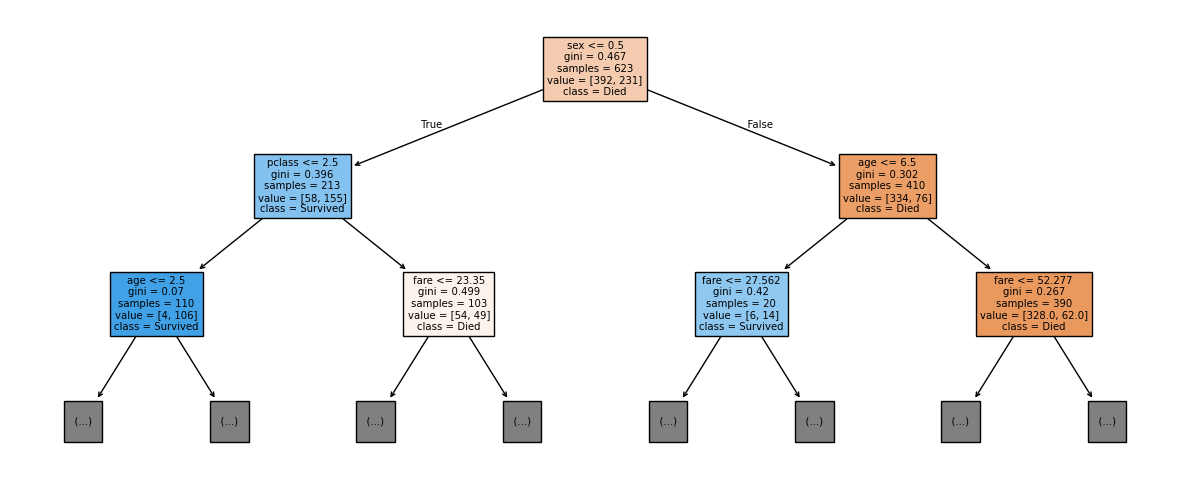

In [96]:
from sklearn.tree import plot_tree

plt.figure(figsize=(12 , 5))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=["Died" , "Survived"],
    filled=True,
    max_depth=2
)

plt.tight_layout()
plt.show()

# Decision Tree with pre-punning

For depth = 2 the accuracy is : 0.7723880597014925
For depth = 3 the accuracy is : 0.8059701492537313
For depth = 4 the accuracy is : 0.8246268656716418


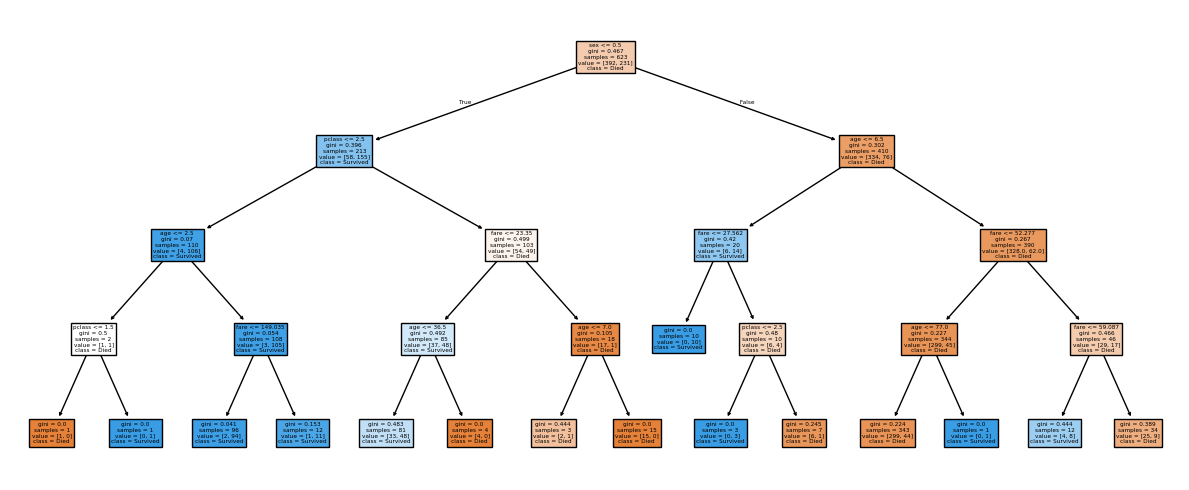

For depth = 5 the accuracy is : 0.7985074626865671
For depth = 6 the accuracy is : 0.7835820895522388
For depth = 7 the accuracy is : 0.7798507462686567
For depth = 8 the accuracy is : 0.7947761194029851
For depth = 9 the accuracy is : 0.7649253731343284
For depth = 10 the accuracy is : 0.8022388059701493


In [105]:
max_depths = [2,3,4,5,6,7,8,9,10]


for depth in max_depths:
    model = DecisionTreeClassifier(max_depth=depth)
    model.fit(X_train,y_train)

    acc = model.score(X_test , y_test)
    print(f"For depth = {depth} the accuracy is : {acc}")

    if depth==4: 
        plt.figure(figsize=(12 , 5))
        plot_tree(
            model,
            feature_names=X.columns,
            class_names=["Died" , "Survived"],
            filled=True,
        )
        
        plt.tight_layout()
        plt.show()

For sample split = 10 the accuracy is : 0.8246268656716418


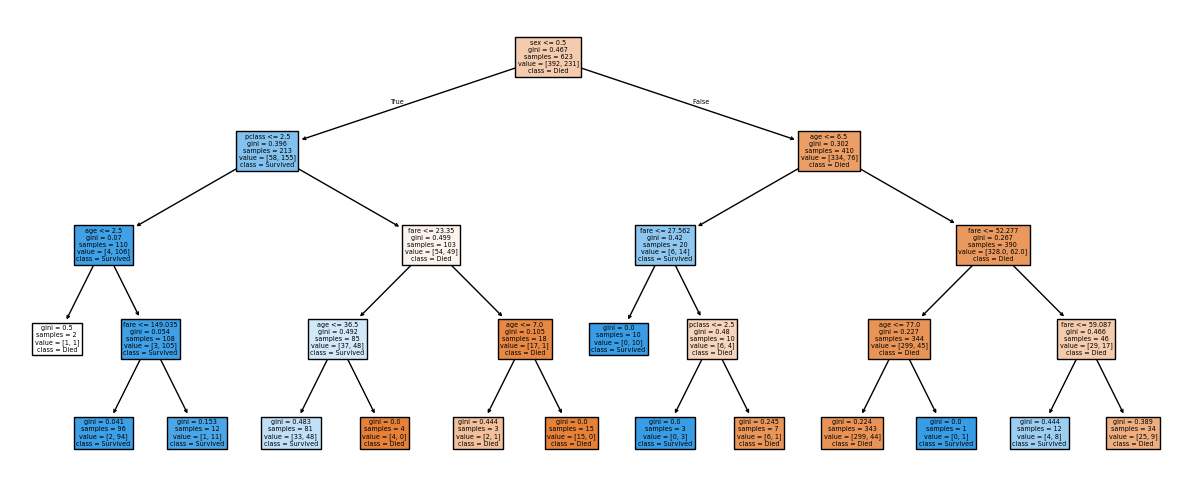

For sample split = 20 the accuracy is : 0.8171641791044776
For sample split = 30 the accuracy is : 0.8208955223880597
For sample split = 40 the accuracy is : 0.8208955223880597
For sample split = 50 the accuracy is : 0.8134328358208955
For sample split = 60 the accuracy is : 0.8134328358208955
For sample split = 70 the accuracy is : 0.8134328358208955
For sample split = 80 the accuracy is : 0.8134328358208955
For sample split = 90 the accuracy is : 0.8097014925373134
For sample split = 100 the accuracy is : 0.8097014925373134


In [107]:
min_samples_splits = [10,20,30,40,50,60,70,80,90,100]


for samples in min_samples_splits:
    model = DecisionTreeClassifier(max_depth=4 , min_samples_split=samples)
    model.fit(X_train,y_train)

    acc = model.score(X_test , y_test)
    print(f"For sample split = {samples} the accuracy is : {acc}")

    if samples==10: 
        plt.figure(figsize=(12 , 5))
        plot_tree(
            model,
            feature_names=X.columns,
            class_names=["Died" , "Survived"],
            filled=True,
        )
        
        plt.tight_layout()
        plt.show()

# Decision Tree with post-punning

In [108]:
full_tree = DecisionTreeClassifier(random_state=42)
full_tree.fit(X_train , y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [109]:
path  = full_tree.cost_complexity_pruning_path(X_train , y_train)
ccp_alphas = path.ccp_alphas
print(ccp_alphas)

[0.00000000e+00 0.00000000e+00 5.73263013e-05 7.64350684e-05
 1.05833172e-04 2.29305205e-04 3.21027287e-04 4.19524296e-04
 4.84088767e-04 5.35045479e-04 5.35045479e-04 5.35045479e-04
 6.42054575e-04 8.56072766e-04 9.17220821e-04 9.63081862e-04
 9.63081862e-04 9.63081862e-04 9.63081862e-04 1.01658641e-03
 1.04193067e-03 1.04779740e-03 1.15926520e-03 1.24357540e-03
 1.29645635e-03 1.32210513e-03 1.33047416e-03 1.33562992e-03
 1.33761370e-03 1.35092931e-03 1.37583123e-03 1.37583123e-03
 1.39800264e-03 1.42678794e-03 1.43227559e-03 1.44145476e-03
 1.49812734e-03 1.50481541e-03 1.51596219e-03 1.52183958e-03
 1.57300793e-03 1.60513644e-03 1.67201712e-03 1.71214553e-03
 1.83444164e-03 1.90119562e-03 1.95673775e-03 2.28286071e-03
 2.33474391e-03 2.40770465e-03 2.60834671e-03 2.63291575e-03
 2.78605824e-03 2.80169269e-03 2.84379161e-03 2.88924559e-03
 3.02412163e-03 4.31143743e-03 4.95299243e-03 5.77849117e-03
 5.89430692e-03 7.42480368e-03 1.23619849e-02 1.78767428e-02
 4.06507445e-02 1.323580

In [110]:
# train our moedl for all the alphas 
tree = []
for alphas in ccp_alphas: 
    model = DecisionTreeClassifier(random_state=42 , ccp_alpha=alphas)
    model.fit(X_train , y_train)
    acc = model.score(X_test , y_test)

    tree.append((model , alphas))

In [111]:
best_alpha = 0
best_acc = 0

for model , alphas in tree:
    cur_acc = model.score(X_test, y_test)
    if cur_acc > best_acc:
        best_acc = cur_acc
        best_alpha = alphas

In [112]:
best_acc

0.8097014925373134

In [113]:
best_alpha

np.float64(0.0015730079278500147)

In [114]:
best_model = DecisionTreeClassifier(random_state=42 , ccp_alpha=best_alpha)
best_model.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


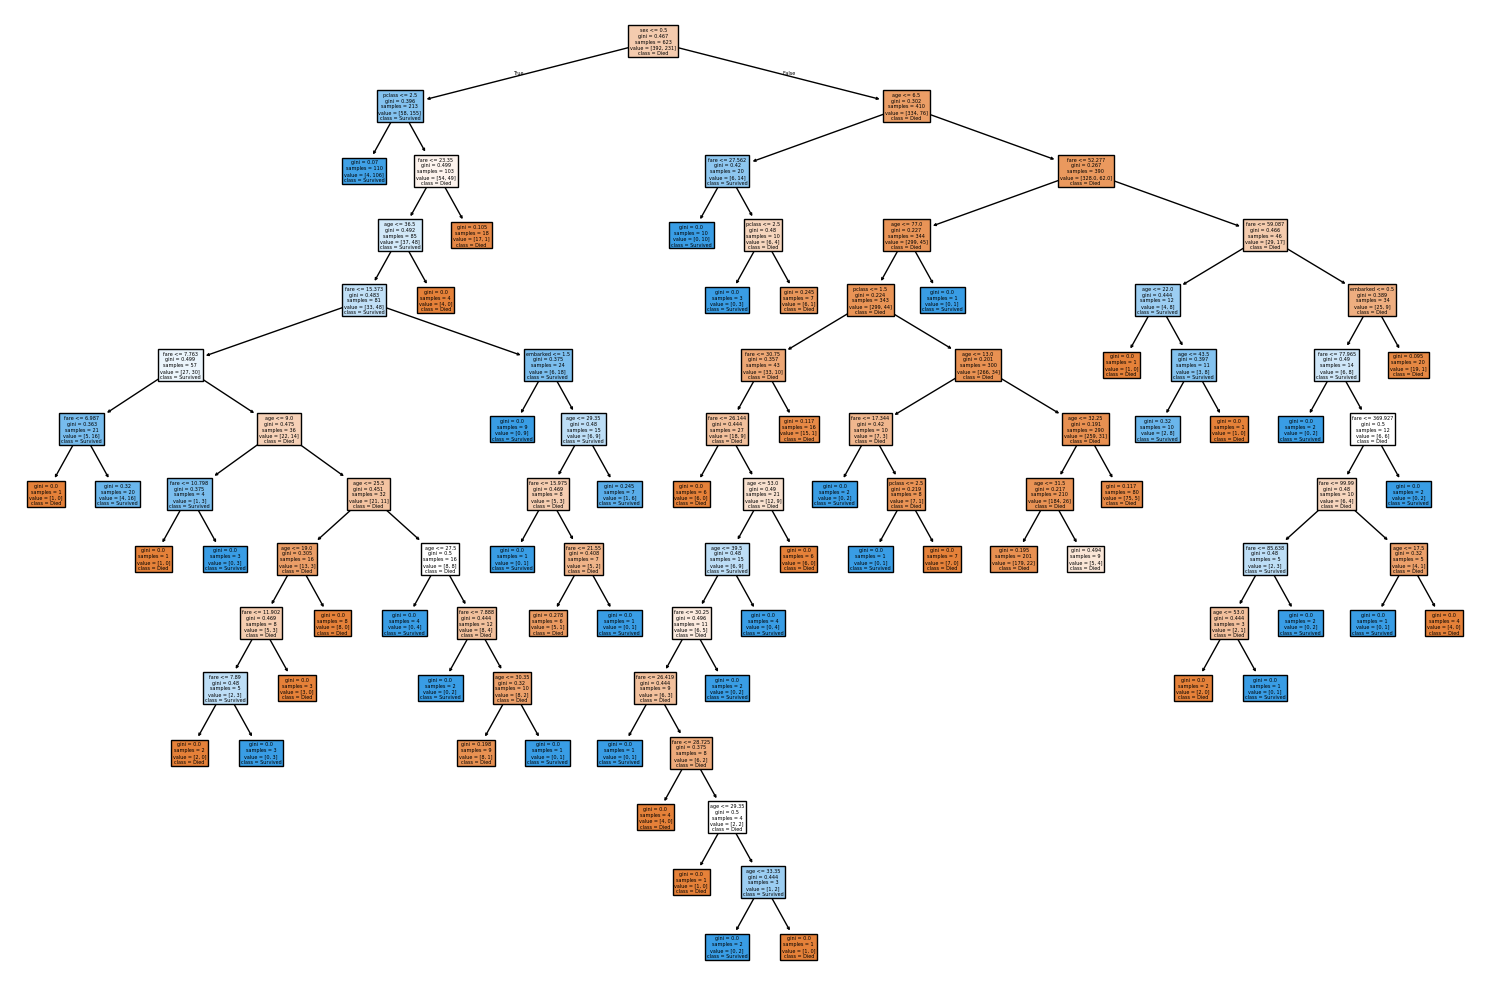

In [119]:
plt.figure(figsize=(15 , 10))
plot_tree(
best_model,
feature_names=X.columns,
class_names=["Died" , "Survived"],
filled=True,
)
        
plt.tight_layout()
plt.show()